<a href="https://colab.research.google.com/github/Anshitha9286/Capstone-project/blob/main/sales_analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sales Analytics Platform: Data Processing and EDA
**Dataset:** Online Retail II (UK online retailer, Dec 2009 to Dec 2011)
**Goal:** Understand, clean and explore the data before building forecasting and customer models.

## 1. Import libraries
Libraries are ready-made toolkits. We import them once at the top so every later step can use them.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 2. Load the dataset
Download the file from Kaggle, then upload it here. We read it into a pandas DataFrame, which is a table with rows and columns.

In [2]:
from google.colab import files
uploaded = files.upload()

Saving online_retail_II.csv to online_retail_II.csv


In [3]:
print(uploaded.keys())

dict_keys(['online_retail_II.csv'])


## 3. Read the data into pandas
CSV and Excel files are read differently. The original dataset has two sheets (2009-2010 and 2010-2011), so for Excel we read both and join them.

In [4]:
df = pd.read_csv("online_retail_II.csv")

In [5]:
print(df.shape)

(1067371, 8)


## 4. First look at the data
Before cleaning anything, we check what each row means, what each column contains, and what types of data we have.

In [6]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


In [8]:
df.describe()

,Quantity,Price,Customer ID
count,"1,067,371.00","1,067,371.00","824,364.00"
mean,9.94,4.65,"15,324.64"
std,172.71,123.55,"1,697.46"
min,"-80,995.00","-53,594.36","12,346.00"
25%,1.00,1.25,"13,975.00"
50%,3.00,2.10,"15,255.00"
75%,10.00,4.15,"16,797.00"
max,"80,995.00","38,970.00","18,287.00"


## 5. Standardize column names
Different versions of this dataset use different column names (Invoice vs InvoiceNo, Price vs UnitPrice, Customer ID vs CustomerID). We rename them so the rest of the code always uses the same names.

In [9]:
df.columns = [c.strip() for c in df.columns]
df = df.rename(columns={"InvoiceNo": "Invoice", "UnitPrice": "Price", "Customer ID": "CustomerID"})
print(df.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'Country']


## 6. Fix data types
Wrong data types cause silent mistakes. Dates stored as text cannot be grouped by month, and customer IDs stored as decimals (like 13085.0) cause problems when joining tables later.

In [10]:
df["Invoice"]     = df["Invoice"].astype(str).str.strip()
df["StockCode"]   = df["StockCode"].astype(str).str.strip().str.upper()
df["Description"] = df["Description"].astype("string").str.strip()
df["Country"]     = df["Country"].astype(str).str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"]  = pd.to_numeric(df["CustomerID"], errors="coerce").astype("Int64")
print(df.dtypes)

Invoice                object
StockCode              object
Description    string[python]
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
CustomerID              Int64
Country                object
dtype: object


## 7. Dataset overview
Time period covered, and how many invoices, products, customers and countries the data contains.

In [11]:
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("Invoices  :", df["Invoice"].nunique())
print("Products  :", df["StockCode"].nunique())
print("Customers :", df["CustomerID"].nunique())
print("Countries :", df["Country"].nunique())

Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Invoices  : 53628
Products  : 5131
Customers : 5942
Countries : 43


In [12]:
df.describe()

,Quantity,InvoiceDate,Price,CustomerID
count,"1,067,371.00",1067371,"1,067,371.00","824,364.00"
mean,9.94,2011-01-02 21:13:55.394028544,4.65,"15,324.64"
min,"-80,995.00",2009-12-01 07:45:00,"-53,594.36","12,346.00"
25%,1.00,2010-07-09 09:46:00,1.25,"13,975.00"
50%,3.00,2010-12-07 15:28:00,2.10,"15,255.00"
75%,10.00,2011-07-22 10:23:00,4.15,"16,797.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,172.71,NaN,123.55,"1,697.46"


**Observations from df.describe()**
- **Size and period:** the dataset has 1,067,371 rows covering 1 Dec 2009 to 9 Dec 2011.
- **Missing customers:** Customer ID has 824,364 values, so 243,007 rows (about 22.8%) have no customer ID. These sales cannot be linked to a customer.
- **Quantity:** ranges from -80,995 to 80,995. Negative values are returns or cancellations. The median is 3 units but the mean is 9.94, so a few very large orders pull the average up.
- **Price:** ranges from -53,594.36 to 38,970.00. A negative price is not a real sale, so these rows are probably accounting adjustments. The median price is £2.10, so the 38,970 maximum is an extreme value that needs checking.
- **Incomplete last month:** the last date is 9 Dec 2011, so December 2011 is only a partial month. It must be excluded from monthly trend charts, or it will look like a sales crash.
- **Conclusion:** the data needs cleaning before analysis. The next step is a data quality audit to measure how many rows each problem affects.

## 8. Data quality audit
We measure each data problem before fixing anything. This lets us say exactly how many rows each issue affects and justify every cleaning decision.

### 8.1 Missing values

In [13]:
missing = df.isna().sum().to_frame("missing")
missing["pct"] = (missing["missing"] / len(df) * 100).round(2)
missing

,missing,pct
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
CustomerID,243007,22.77
Country,0,0.00


### 8.2 Duplicate rows
A duplicate is a row identical to another row in every column. Duplicates would count the same sale twice and inflate revenue.

In [14]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 34335


### 8.3 Cancellation invoices
Invoice numbers starting with "C" are cancellations or returns, not sales. If they stay in, revenue will be understated.

In [15]:
is_cancel = df["Invoice"].str.startswith("C")
print("Cancellation rows:", is_cancel.sum())
df[is_cancel].head()

Cancellation rows: 19494


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321,Australia


### 8.4 Invalid quantities and prices
A real sale has a positive quantity and a positive price. Anything else is a return, a stock adjustment or an accounting entry.

In [16]:
print("Quantity <= 0 :", (df["Quantity"] <= 0).sum())
print("Price <= 0    :", (df["Price"] <= 0).sum())

Quantity <= 0 : 22950
Price <= 0    : 6207


In [17]:
df[df["Price"] < 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,"-53,594.36",<NA>,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,"-44,031.79",<NA>,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,"-38,925.87",<NA>,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,"-11,062.06",<NA>,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,"-11,062.06",<NA>,United Kingdom


In [18]:
df.sort_values("Quantity", ascending=False).head(5)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902,Denmark
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902,Denmark


### 8.5 Non-product stock codes
Real products have codes that start with 5 digits (like 85123A). Other codes, such as postage or bank charges, are fees and manual entries. They are not products and would distort product analysis.

In [19]:
non_product = ~df["StockCode"].str.match(r"^\d{5}")
print("Non-product rows:", non_product.sum())
df.loc[non_product, "StockCode"].value_counts().head(10)

Non-product rows: 6093


,count
StockCode,
POST,2122
DOT,1446
M,1426
C2,282
D,177
S,104
BANK CHARGES,102
ADJUST,67
AMAZONFEE,43


In [20]:
top_codes = df.loc[non_product, "StockCode"].value_counts().head(10).index
df.loc[non_product].groupby("StockCode")["Description"].first().loc[top_codes]

,Description
StockCode,
POST,POSTAGE
DOT,DOTCOM POSTAGE
M,Manual
C2,CARRIAGE
D,Discount
S,SAMPLES
BANK CHARGES,Bank Charges
ADJUST,Adjustment by john on 26/01/2010 16
AMAZONFEE,AMAZON FEE


### 8.6 Audit summary
All the problems in one table. A row can appear in more than one issue (for example a cancellation also has a negative quantity), so the rows do not add up to a total.

In [21]:
n = len(df)
audit = pd.DataFrame({
    "issue": ["Missing Customer ID", "Missing Description", "Duplicate rows",
              "Cancellation invoices (C...)", "Quantity <= 0", "Price <= 0",
              "Non-product stock codes"],
    "rows": [df["CustomerID"].isna().sum(), df["Description"].isna().sum(),
             df.duplicated().sum(), is_cancel.sum(),
             (df["Quantity"] <= 0).sum(), (df["Price"] <= 0).sum(),
             non_product.sum()],
})
audit["% of rows"] = (audit["rows"] / n * 100).round(2)
audit

,issue,rows,% of rows
0,Missing Customer ID,243007,22.77
1,Missing Description,4382,0.41
2,Duplicate rows,34335,3.22
3,Cancellation invoices (C...),19494,1.83
4,Quantity <= 0,22950,2.15
5,Price <= 0,6207,0.58
6,Non-product stock codes,6093,0.57


**Observations from the audit**
- **Missing Customer ID is the largest issue:** 243,007 rows (22.77%). These are real sales, so they are kept for revenue analysis and excluded only from customer analysis (RFM, churn).
- **Duplicates:** 34,335 rows (3.22%) are identical in every column. Assumption: an identical row on the same invoice is a double entry, so they will be dropped.
- **Cancellations:** 19,494 rows (1.83%) have invoice numbers starting with C. They will be moved to a separate returns table.
- **Quantity <= 0 affects 22,950 rows, more than the 19,494 cancellations.** So about 3,456 rows have zero or negative quantity without being cancellations, probably stock adjustments.
- **Price <= 0 affects 6,207 rows.** Only 5 have a negative price. All five are "Adjust bad debt" entries (stock code B, invoices starting with A, no customer ID) from -£11,062 to -£53,594. They are accounting entries, not sales.
- **Non-product stock codes:** 6,093 rows (0.57%). The most common are POST, DOT, M, C2, D, S, BANK CHARGES, ADJUST and AMAZONFEE, which look like postage, manual entries, fees and discounts, not products.
- **Extreme quantities:** the largest line is 80,995 units (PAPER CRAFT, LITTLE BIRDIE) and the smallest quantity in the data is -80,995. The same size suggests an order that was cancelled, which needs checking.
- **Conclusion:** none of these problems is deleted blindly. Each one is moved to its own table or handled with a logged decision.

## 9. Data cleaning
Every cleaning step is logged. Problems are moved to separate tables instead of deleted, so nothing is lost and every decision can be explained.

| Problem | Decision | Reason |
|---|---|---|
| Duplicate rows | Drop | Counting the same sale twice inflates revenue |
| Cancellations (C...) | Move to a `returns` table | Returns are useful to analyze but are not sales |
| Quantity or Price <= 0 | Move to an `adjustments` table | Stock write-offs and accounting entries, not sales |
| Non-product codes | Move to a `non_products` table | Postage and fees are not products |
| Missing Description | Fill from the same stock code | A product keeps one name |
| Missing Customer ID | Keep | Still a valid sale |

In [22]:
work = df.copy()
log = []

def record(step, before, after):
    log.append({"step": step, "rows_before": before,
                "rows_after": after, "rows_removed": before - after})

In [23]:
b = len(work)
work = work.drop_duplicates()
record("Drop exact duplicate rows", b, len(work))

In [24]:
b = len(work)
cancel_mask = work["Invoice"].str.startswith("C")
returns = work[cancel_mask].copy()
work = work[~cancel_mask]
record("Move cancellation invoices to returns table", b, len(work))

In [25]:
b = len(work)
bad_mask = (work["Quantity"] <= 0) | (work["Price"] <= 0)
adjustments = work[bad_mask].copy()
work = work[~bad_mask]
record("Move Quantity<=0 or Price<=0 rows to adjustments table", b, len(work))

In [26]:
b = len(work)
np_mask = ~work["StockCode"].str.match(r"^\d{5}")
non_products = work[np_mask].copy()
work = work[~np_mask]
record("Move non-product stock codes to non_products table", b, len(work))

In [27]:
b = len(work)
work["Description"] = work["Description"].str.upper().str.strip()
best_desc = (work.dropna(subset=["Description"])
                 .groupby("StockCode")["Description"]
                 .agg(lambda s: s.mode().iloc[0]))
work["Description"] = work["Description"].fillna(work["StockCode"].map(best_desc))
still_missing = work["Description"].isna().sum()
work["Description"] = work["Description"].fillna("UNKNOWN")
record(f"Fill missing descriptions ({still_missing} left as UNKNOWN)", b, len(work))

In [28]:
b = len(work)
work = work.drop_duplicates()
record("Drop duplicates revealed after fixing descriptions", b, len(work))

In [29]:
sales = work.reset_index(drop=True)
decision_log = pd.DataFrame(log)
decision_log

,step,rows_before,rows_after,rows_removed
0,Drop exact duplicate rows,1067371,1033036,34335
1,Move cancellation invoices to returns table,1033036,1013932,19104
2,Move Quantity<=0 or Price<=0 rows to adjustmen...,1013932,1007913,6019
3,Move non-product stock codes to non_products t...,1007913,1003214,4699
4,Fill missing descriptions (0 left as UNKNOWN),1003214,1003214,0
5,Drop duplicates revealed after fixing descript...,1003214,1003214,0


In [30]:
print(f"Started with {len(df):,} rows. Clean sales table: {len(sales):,} rows ({len(sales)/len(df):.1%} kept).")
print(f"Returns: {len(returns):,} | Adjustments: {len(adjustments):,} | Non-products: {len(non_products):,}")

Started with 1,067,371 rows. Clean sales table: 1,003,214 rows (94.0% kept).
Returns: 19,104 | Adjustments: 6,019 | Non-products: 4,699


### 9.1 Validation checks
Automatic tests that confirm the cleaned table follows our rules. If any test fails, the notebook stops with an error.

In [31]:
checks = {
    "No duplicate rows":             sales.duplicated().sum() == 0,
    "No cancellation invoices":      (~sales["Invoice"].str.startswith("C")).all(),
    "All quantities positive":       (sales["Quantity"] > 0).all(),
    "All prices positive":           (sales["Price"] > 0).all(),
    "No missing descriptions":       sales["Description"].notna().all(),
}
for name, passed in checks.items():
    print("PASS" if passed else "FAIL", "-", name)
assert all(checks.values()), "A validation check failed. Review the cleaning steps."

PASS - No duplicate rows
PASS - No cancellation invoices
PASS - All quantities positive
PASS - All prices positive
PASS - No missing descriptions


**Observations from cleaning**
- The clean sales table has 1,003,214 rows, 94.0% of the original 1,067,371.
- Duplicates were the largest removal (34,335 rows), followed by cancellations (19,104), adjustments (6,019) and non-product codes (4,699).
- Returns, adjustments and non-products were set aside in their own tables, not deleted, so nothing is lost and each decision can be explained.
- All missing descriptions disappeared during earlier steps, because those rows were duplicates, adjustments or non-products. None was left to label UNKNOWN.
- Rows with a missing Customer ID are still in the table. They are valid sales and will be excluded only from customer-level analysis.
- All five validation checks passed: no duplicates, no cancellations, positive quantities, positive prices and no missing descriptions.

## 10. Feature engineering
New columns that every later analysis needs: revenue, and date parts for trend, seasonality and peak-time analysis.

In [32]:
sales["Revenue"]   = sales["Quantity"] * sales["Price"]
sales["Date"]      = sales["InvoiceDate"].dt.normalize()
sales["YearMonth"] = sales["InvoiceDate"].dt.to_period("M")
sales["Year"]      = sales["InvoiceDate"].dt.year
sales["Month"]     = sales["InvoiceDate"].dt.month
sales["DayName"]   = sales["InvoiceDate"].dt.day_name()
sales["Hour"]      = sales["InvoiceDate"].dt.hour
sales.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,Revenue,Date,YearMonth,Year,Month,DayName,Hour
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.40,2009-12-01,2009-12,2009,12,Tuesday,7
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.00,2009-12-01,2009-12,2009,12,Tuesday,7
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.00,2009-12-01,2009-12,2009,12,Tuesday,7
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.80,2009-12-01,2009-12,2009,12,Tuesday,7
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.00,2009-12-01,2009-12,2009,12,Tuesday,7


### 10.1 Flag very large orders
A few lines have huge quantities. We keep them but flag them, so charts and models can handle them with care.

In [33]:
q_cut = sales["Quantity"].quantile(0.999)
sales["IsBulkLine"] = sales["Quantity"] > q_cut
print(f"Bulk threshold: {q_cut:,.0f} units -> {sales['IsBulkLine'].sum():,} lines flagged")

Bulk threshold: 500 units -> 948 lines flagged


In [34]:
returns["Revenue"]   = returns["Quantity"] * returns["Price"]
returns["YearMonth"] = returns["InvoiceDate"].dt.to_period("M")

### 10.2 Check the extreme orders
The largest lines (80,995 and 74,215 units) may have been cancelled. If a cancelled order stays in the sales table, revenue is overstated.

In [35]:
big = sales.sort_values("Quantity", ascending=False).head(5)
big[["Invoice", "Description", "Quantity", "Price", "InvoiceDate", "CustomerID", "Revenue"]]

,Invoice,Description,Quantity,Price,InvoiceDate,CustomerID,Revenue
1001747,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00,16446,"168,469.60"
540112,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00,12346,"77,183.60"
86700,497946,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,2010-02-15 11:57:00,13902,"1,915.20"
121306,501534,SET/6 WOODLAND PAPER PLATES,12960,0.10,2010-03-17 13:09:00,13902,"1,296.00"
121304,501534,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,2010-03-17 13:09:00,13902,"1,296.00"


In [36]:
returns[returns["Quantity"].abs().isin([80995, 74215])]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,Revenue,YearMonth
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom,"-77,183.60",2011-01
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,United Kingdom,"-168,469.60",2011-12


**Observations from the extreme-order check**
- The two largest lines in the data were placed and then cancelled within minutes: 74,215 jars (invoice 541431, customer 12346, 18 Jan 2011) and 80,995 paper crafts (invoice 581483, customer 16446, 9 Dec 2011). Together they account for £245,653.20 of revenue that never happened.
- A match on customer, product, price, date and quantity found 26 more bulk lines that were returned in full on the same day, worth £29,318.40. In total, 28 lines (£274,971.60) were never real sales.
- Decision: these orders are moved out of both the sales and returns tables into `cancelled_orders` and `cancelled_returns`. Ordinary returns of earlier purchases stay in `returns`, because that revenue did happen before it was returned.

## 11. Cancelled bulk orders
A bulk order cancelled in full on the same day was never a real sale. We first identify them, review the list, then move them out.

In [37]:
def fingerprint(d, qty_sign):
    return (d["CustomerID"].astype(str) + "|" + d["StockCode"] + "|"
            + d["Price"].astype(str) + "|" + d["InvoiceDate"].dt.normalize().astype(str)
            + "|" + (qty_sign * d["Quantity"]).astype(str))

bulk       = sales[sales["IsBulkLine"]]
bulk_fp    = fingerprint(bulk, 1)
returns_fp = fingerprint(returns, -1)

cancelled_idx = bulk_fp[bulk_fp.isin(set(returns_fp))].index
print(f"Cancelled bulk lines: {len(cancelled_idx)} | revenue: £{sales.loc[cancelled_idx, 'Revenue'].sum():,.2f}")
sales.loc[cancelled_idx, ["Invoice", "Description", "Quantity", "InvoiceDate", "CustomerID", "Revenue"]]

Cancelled bulk lines: 28 | revenue: £274,971.60


,Invoice,Description,Quantity,InvoiceDate,CustomerID,Revenue
8382,490091,PINK BLUE FELT CRAFT TRINKET BOX,600,2009-12-03 15:54:00,17949,636.00
8383,490094,ROSES ON BLUE TEACUP CANDLE,504,2009-12-03 15:56:00,17949,851.76
188288,508333,PINK FAIRY CAKE COASTER,1200,2010-05-14 12:00:00,13694,864.00
214818,511164,LUNCH BAG CARS BLUE,830,2010-06-07 12:02:00,14028,"1,203.50"
214819,511164,LUNCH BAG BLACK SKULL.,830,2010-06-07 12:02:00,14028,"1,203.50"
214820,511164,LUNCH BAG WOODLAND,830,2010-06-07 12:02:00,14028,"1,203.50"
214872,511176,LUNCH BAG CARS BLUE,830,2010-06-07 12:09:00,14028,"1,203.50"
214873,511176,LUNCH BAG BLACK SKULL.,830,2010-06-07 12:09:00,14028,"1,203.50"
214874,511176,LUNCH BAG WOODLAND,830,2010-06-07 12:09:00,14028,"1,203.50"
239939,513653,BAG 250G SWIRLY MARBLES,648,2010-06-28 09:55:00,16754,466.56


In [38]:
b = len(sales)
cancelled_fps    = set(bulk_fp.loc[cancelled_idx])
return_twin_mask = returns_fp.isin(cancelled_fps)

cancelled_orders  = sales.loc[cancelled_idx].copy()
cancelled_returns = returns[return_twin_mask].copy()

sales   = sales.drop(index=cancelled_idx).reset_index(drop=True)
returns = returns[~return_twin_mask].reset_index(drop=True)

record("Move same-day cancelled bulk orders to cancelled_orders", b, len(sales))
pd.DataFrame(log)

,step,rows_before,rows_after,rows_removed
0,Drop exact duplicate rows,1067371,1033036,34335
1,Move cancellation invoices to returns table,1033036,1013932,19104
2,Move Quantity<=0 or Price<=0 rows to adjustmen...,1013932,1007913,6019
3,Move non-product stock codes to non_products t...,1007913,1003214,4699
4,Fill missing descriptions (0 left as UNKNOWN),1003214,1003214,0
5,Drop duplicates revealed after fixing descript...,1003214,1003214,0
6,Move same-day cancelled bulk orders to cancell...,1003214,1003186,28


## 12. Exploratory data analysis
Now that the data is clean, we measure the business: how much it sold, to how many customers, and how often orders were returned.

### 12.1 Headline KPIs

In [39]:
total_revenue   = sales["Revenue"].sum()
total_orders    = sales["Invoice"].nunique()
total_customers = sales["CustomerID"].nunique()
total_units     = sales["Quantity"].sum()
aov             = total_revenue / total_orders
returns_value   = -returns["Revenue"].sum()
return_rate     = returns_value / total_revenue

kpis = pd.DataFrame({
    "KPI": ["Total revenue", "Orders", "Customers (known IDs)", "Units sold",
            "Average order value", "Returned value", "Return rate"],
    "Value": [f"£{total_revenue:,.0f}", f"{total_orders:,}", f"{total_customers:,}",
              f"{total_units:,}", f"£{aov:,.2f}", f"£{returns_value:,.0f}", f"{return_rate:.1%}"]
})
kpis

,KPI,Value
0,Total revenue,"£19,367,721"
1,Orders,"39,510"
2,Customers (known IDs),"5,852"
3,Units sold,"11,010,862"
4,Average order value,£490.20
5,Returned value,"£1,190,970"
6,Return rate,6.1%


**Observations: headline KPIs**
- The business made £19.37M from 39,510 orders and 11.0M units, sold to 5,852 identified customers over 24 months.
- The average order value is £490.20. That is high for a gift retailer, which suggests many orders are wholesale purchases by trade customers, not single-shopper baskets.
- Returns total £1.19M, which is 6.1% of sales. This is worth tracking by month and by product later.
- Customer counts only include rows with a Customer ID. About 22.8% of the original rows had none, so customer-level numbers describe most, but not all, of the sales.

### 12.2 Monthly revenue trend
Revenue per month shows growth and seasonality. December 2011 is excluded because the data stops on 9 December, so the month is incomplete and would look like a crash.

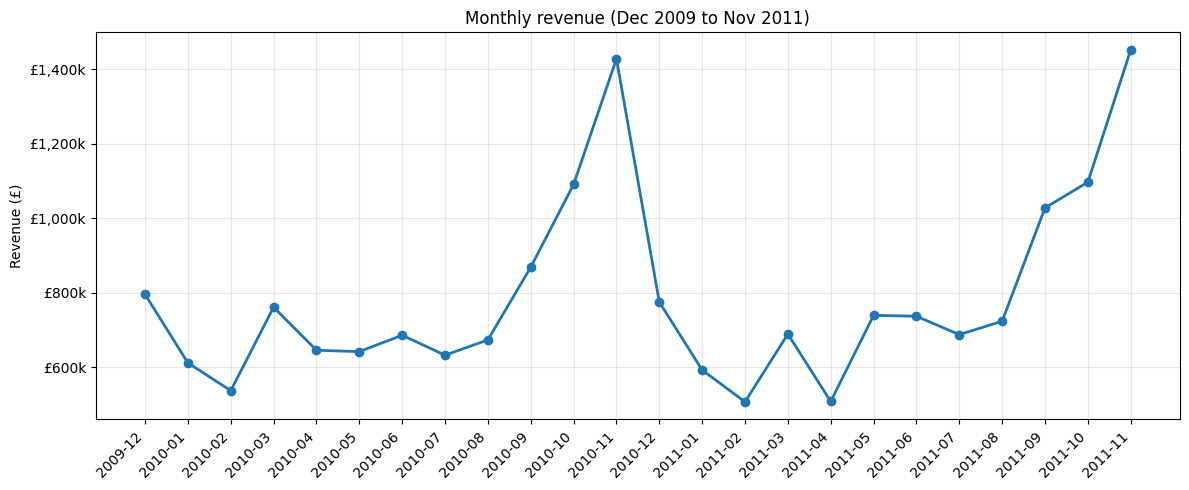

In [40]:
from matplotlib.ticker import FuncFormatter

monthly = sales.groupby("YearMonth")["Revenue"].sum()
monthly = monthly[monthly.index < pd.Period("2011-12")]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index.astype(str), monthly.values, marker="o", linewidth=2)
ax.set_title("Monthly revenue (Dec 2009 to Nov 2011)")
ax.set_ylabel("Revenue (£)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v/1000:,.0f}k"))
ax.grid(alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Observations: monthly revenue**
- Revenue follows a strong seasonal pattern. It is flat at roughly £500k to £800k a month from January to August, then climbs from September to a peak in November.
- November is the biggest month in both years: about £1.43M in 2010 and about £1.45M in 2011, roughly double a typical spring or summer month.
- December 2010 drops sharply to about £775k. The data stops on 9 December 2011, so December is excluded from this chart.
- The lowest months are February and April 2011, at about £505k to £510k.
- The Sept to Nov build-up repeats each year, so a forecasting model must learn this seasonality.

### 12.3 Seasonality: 2010 vs 2011
Plotting the same months of each year on one chart shows whether the seasonal pattern repeats, and whether 2011 is growing against 2010.

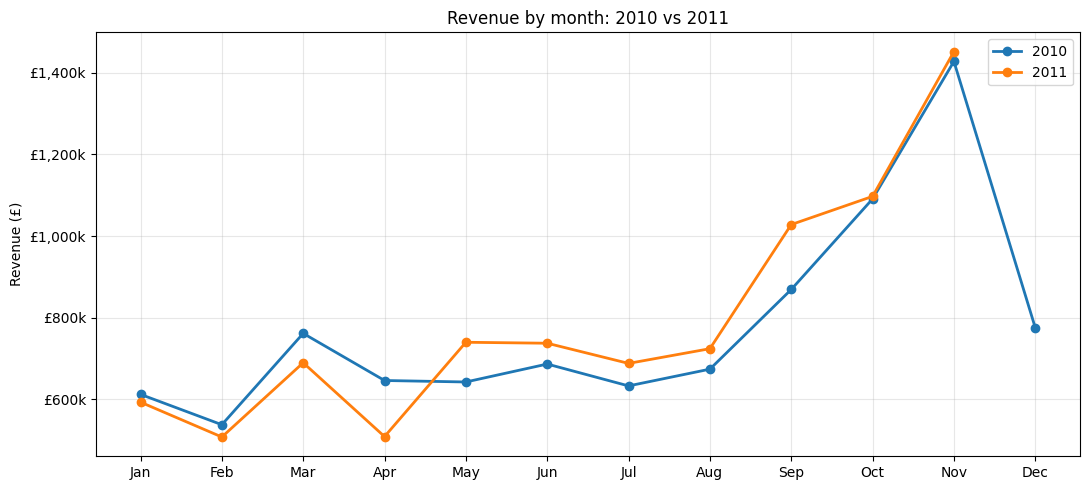

In [41]:
full = sales[sales["YearMonth"] < pd.Period("2011-12")]
season = full.pivot_table(index="Month", columns="Year", values="Revenue", aggfunc="sum")[[2010, 2011]]
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(11, 5))
for yr in [2010, 2011]:
    ax.plot(season.index, season[yr], marker="o", linewidth=2, label=str(yr))
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
ax.set_title("Revenue by month: 2010 vs 2011")
ax.set_ylabel("Revenue (£)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v/1000:,.0f}k"))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 12.4 Orders and average order value
Revenue is orders multiplied by the average spend per order. Splitting them shows whether growth comes from more orders or bigger baskets.

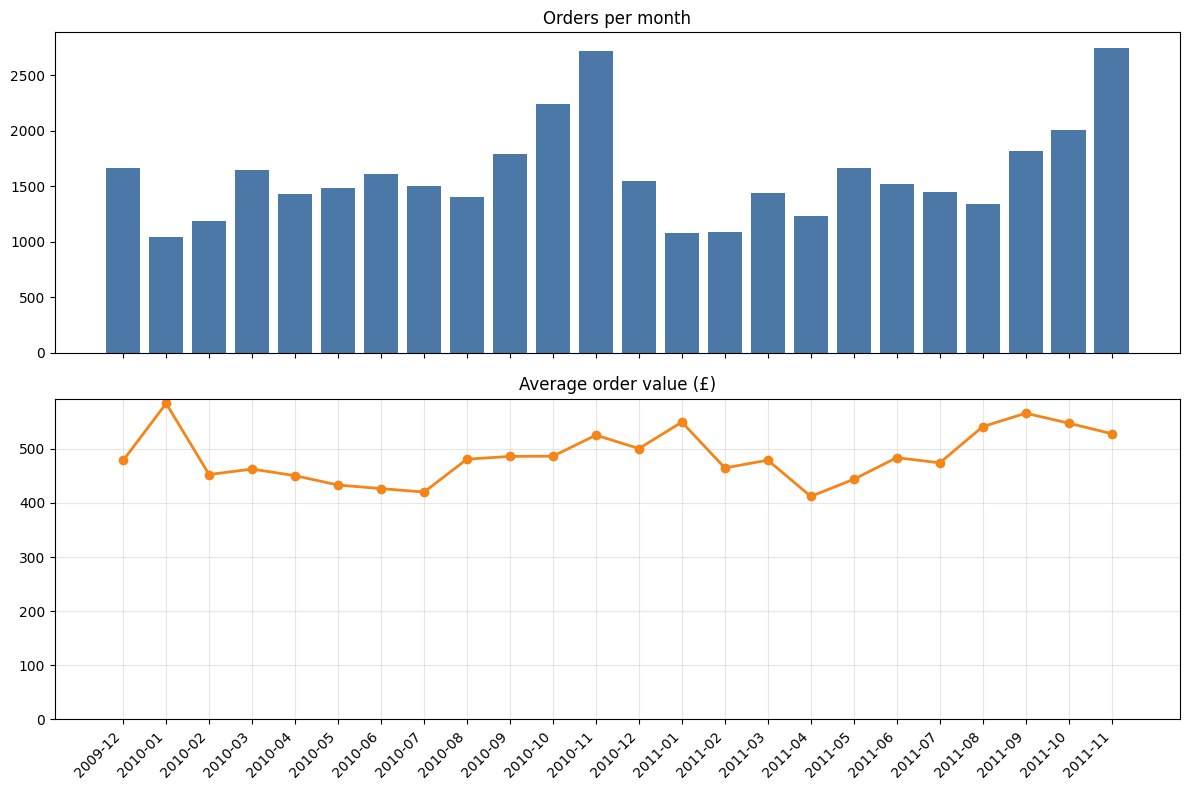

,Revenue,Orders,AOV
YearMonth,,,
2011-11,"1,452,112.69",2751,527.85
2010-11,"1,428,107.71",2719,525.23
2011-10,"1,097,379.60",2005,547.32


In [42]:
m = full.groupby("YearMonth").agg(Revenue=("Revenue", "sum"), Orders=("Invoice", "nunique"))
m["AOV"] = m["Revenue"] / m["Orders"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax1.bar(m.index.astype(str), m["Orders"], color="#4c78a8")
ax1.set_title("Orders per month")
ax2.plot(m.index.astype(str), m["AOV"], marker="o", linewidth=2, color="#f58518")
ax2.set_title("Average order value (£)")
ax2.set_ylim(0, None)
ax2.grid(alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

m.sort_values("Revenue", ascending=False).head(3)

**Observations: orders and average order value**
- The three highest-revenue months are Nov 2011 (£1.45M, 2,751 orders), Nov 2010 (£1.43M, 2,719 orders) and Oct 2011 (£1.10M, 2,005 orders).
- Order volume drives the seasonal peak. Orders rise from about 1,400 to 1,500 a month in summer to more than 2,700 in November, an increase of roughly 80%. They then fall back to about 1,500 in December and about 1,080 in January.
- Average order value moves much less. It rises from about £420 to £480 in mid-year to £525 to £570 in autumn, an increase of roughly 25%. Higher AOV adds to the peak, but order count explains most of it.
- AOV ranges from about £410 (April 2011) to about £585 (January 2010). January 2010 combines low order volume (about 1,040 orders) with a high AOV, which suggests a few large trade orders in a quiet month.
- Orders in November 2011 (2,751) are almost the same as in November 2010 (2,719), so the peak-season order count did not grow year on year.